# PhishGuard AI — Dataset & Model Analysis

**Dataset:** UCI PhiUSIIL Phishing URL (Website) Dataset  
**Purpose:** Explore the dataset, inspect the saved model, check feature compatibility, and evaluate the model when the actual project files are available.

> This notebook calculates results from your local CSV and model. It does not invent dataset counts or performance metrics.

## 1. Analysis objectives
- Inspect dataset dimensions, columns, data types, missing values, duplicates, and class distribution.
- Explore selected URL and website features.
- Inspect the saved Scikit-learn model and its expected input columns.
- Check whether the dataset schema matches the model.
- Run a stratified hold-out evaluation only when required columns are available.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42

# Detect the main project folder
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name == "Notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATASET_PATH = (
    PROJECT_ROOT
    / "phiusiil+phishing+url+dataset"
    / "PhiUSIIL_Phishing_URL_Dataset.csv"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "Phish_Trained_Model"
    / "phishing_model.pkl"
)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATASET_PATH.exists())
print("Model exists:", MODEL_PATH.exists())

Project root: C:\Users\Jaideep\Desktop\YMCA COLLEGE BCA\MINOR PROJECT\PhishGuard AI
Dataset exists: True
Model exists: True


## 2. Load dataset

In [2]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}"
    )

df = pd.read_csv(DATASET_PATH, low_memory=False)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


## 3. Dataset structure and quality

In [3]:
print("Columns:")
for col in df.columns:
    print("-", col)
print("\\nData types:")
display(df.dtypes.astype(str).to_frame("dtype"))
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=False),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)
display(quality)
print("Duplicate rows:", int(df.duplicated().sum()))

Columns:
- FILENAME
- URL
- URLLength
- Domain
- DomainLength
- IsDomainIP
- TLD
- URLSimilarityIndex
- CharContinuationRate
- TLDLegitimateProb
- URLCharProb
- TLDLength
- NoOfSubDomain
- HasObfuscation
- NoOfObfuscatedChar
- ObfuscationRatio
- NoOfLettersInURL
- LetterRatioInURL
- NoOfDegitsInURL
- DegitRatioInURL
- NoOfEqualsInURL
- NoOfQMarkInURL
- NoOfAmpersandInURL
- NoOfOtherSpecialCharsInURL
- SpacialCharRatioInURL
- IsHTTPS
- LineOfCode
- LargestLineLength
- HasTitle
- Title
- DomainTitleMatchScore
- URLTitleMatchScore
- HasFavicon
- Robots
- IsResponsive
- NoOfURLRedirect
- NoOfSelfRedirect
- HasDescription
- NoOfPopup
- NoOfiFrame
- HasExternalFormSubmit
- HasSocialNet
- HasSubmitButton
- HasHiddenFields
- HasPasswordField
- Bank
- Pay
- Crypto
- HasCopyrightInfo
- NoOfImage
- NoOfCSS
- NoOfJS
- NoOfSelfRef
- NoOfEmptyRef
- NoOfExternalRef
- label
\nData types:


,dtype
FILENAME,str
URL,str
URLLength,int64
Domain,str
DomainLength,int64
IsDomainIP,int64
TLD,str
URLSimilarityIndex,float64
CharContinuationRate,float64
TLDLegitimateProb,float64


,missing_count,missing_percent,unique_values,dtype
FILENAME,0,0.0,235795,str
URL,0,0.0,235370,str
URLLength,0,0.0,482,int64
Domain,0,0.0,220086,str
DomainLength,0,0.0,101,int64
IsDomainIP,0,0.0,2,int64
TLD,0,0.0,695,str
URLSimilarityIndex,0,0.0,36360,float64
CharContinuationRate,0,0.0,898,float64
TLDLegitimateProb,0,0.0,465,float64


Duplicate rows: 0


## 4. Target distribution

,row_count
label,
0,100945
1,134850


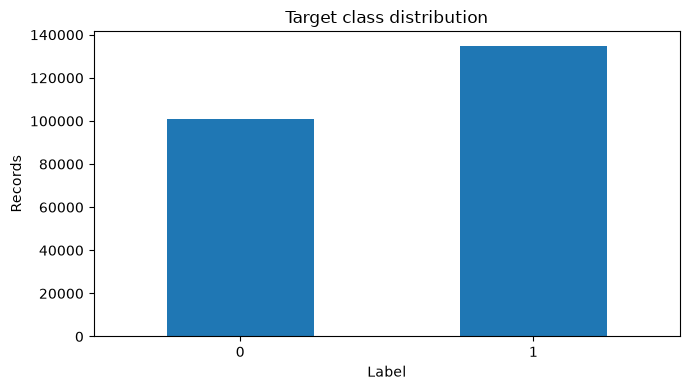

Confirm numeric label meanings from the dataset documentation and training code.


In [4]:
TARGET_COLUMN = "label"
if TARGET_COLUMN not in df.columns:
    raise KeyError(f"Target column '{TARGET_COLUMN}' was not found.")
label_counts = df[TARGET_COLUMN].value_counts(dropna=False).sort_index()
display(label_counts.to_frame("row_count"))
ax = label_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Target class distribution")
ax.set_xlabel("Label")
ax.set_ylabel("Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Confirm numeric label meanings from the dataset documentation and training code.")

## 5. Descriptive statistics

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
if numeric_columns:
    display(df[numeric_columns].describe().T)
else:
    print("No numeric columns found.")

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


## 6. Selected feature distributions

Available features: ['URLLength', 'DomainLength', 'NoOfSubDomain', 'NoOfLettersInURL', 'NoOfDegitsInURL', 'NoOfOtherSpecialCharsInURL', 'IsHTTPS', 'HasObfuscation', 'NoOfObfuscatedChar', 'NoOfURLRedirect', 'NoOfPopup', 'NoOfiFrame']


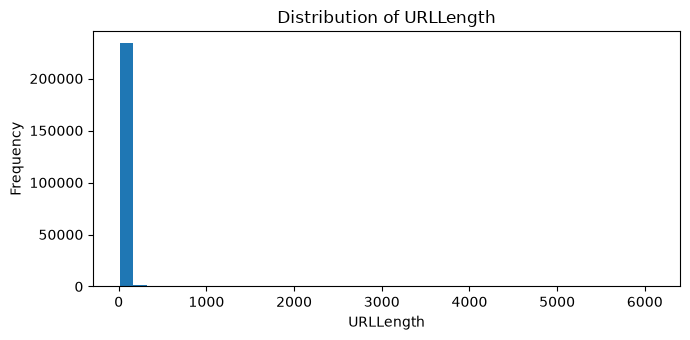

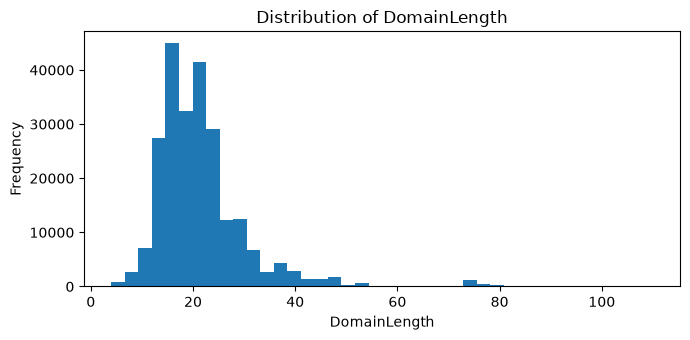

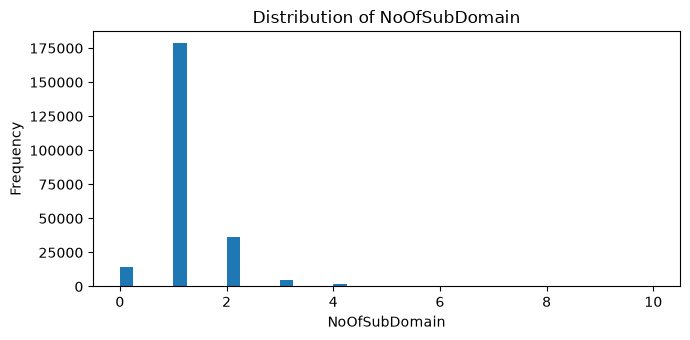

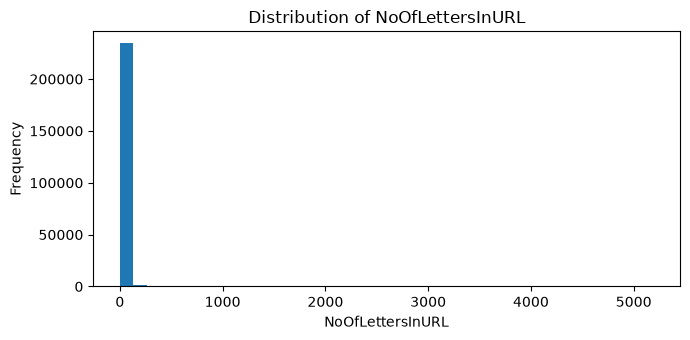

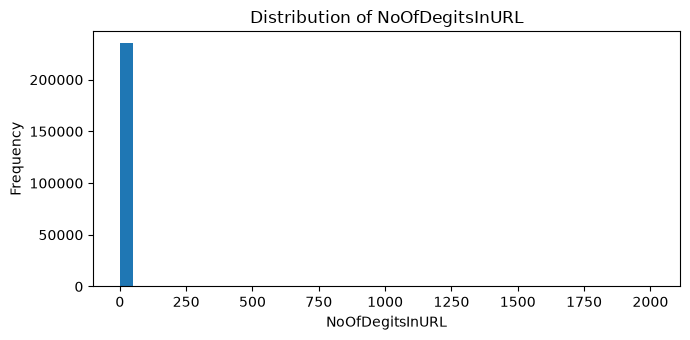

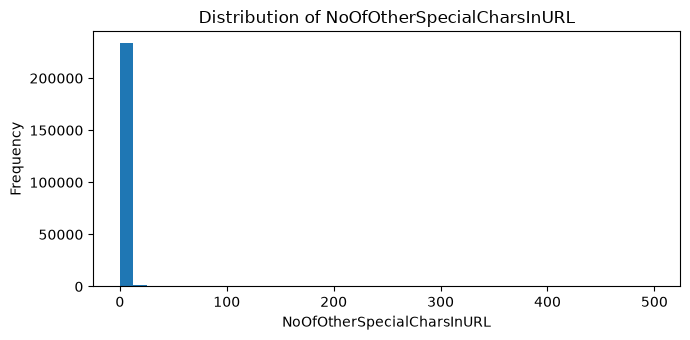

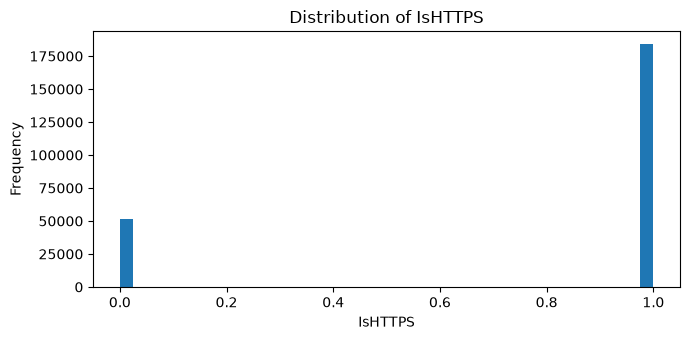

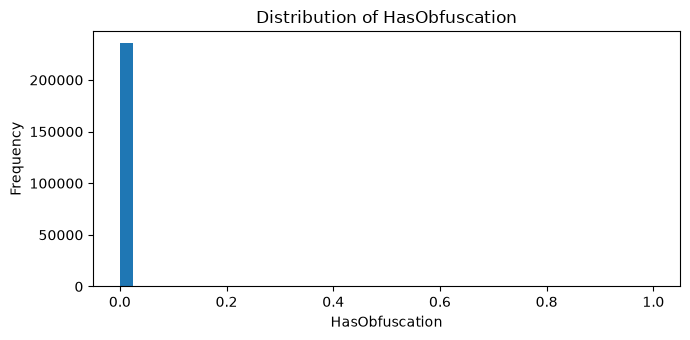

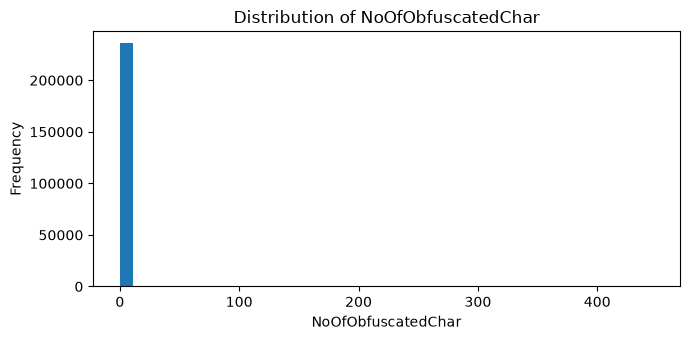

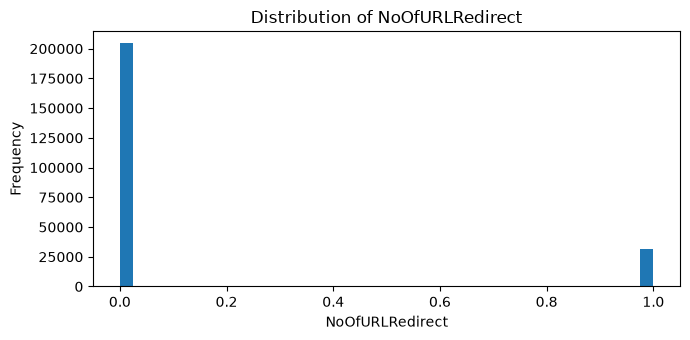

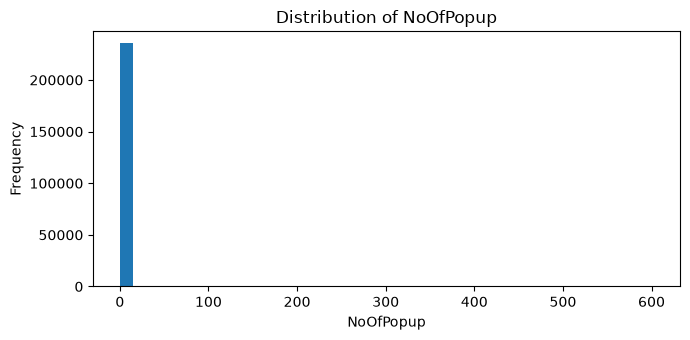

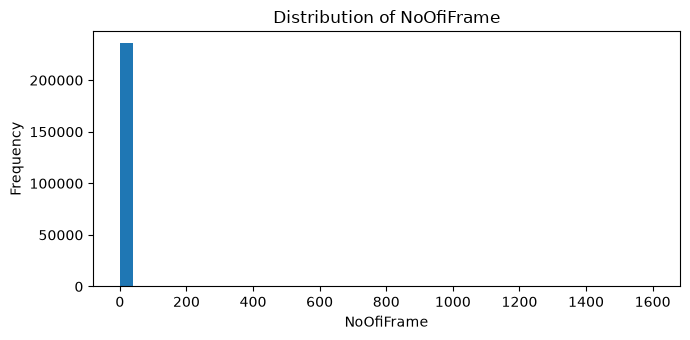

In [6]:
candidate_features = [
    "URLLength", "DomainLength", "NoOfSubDomain",
    "NoOfLettersInURL", "NoOfDegitsInURL",
    "NoOfOtherSpecialCharsInURL", "IsHTTPS",
    "HasObfuscation", "NoOfObfuscatedChar",
    "NoOfURLRedirect", "NoOfPopup", "NoOfiFrame"
]
available_features = [c for c in candidate_features if c in df.columns]
print("Available features:", available_features)
for feature in available_features:
    values = pd.to_numeric(df[feature], errors="coerce").dropna()
    if values.empty:
        continue
    plt.figure(figsize=(7, 3.5))
    plt.hist(values, bins=40)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 7. Numeric feature correlation

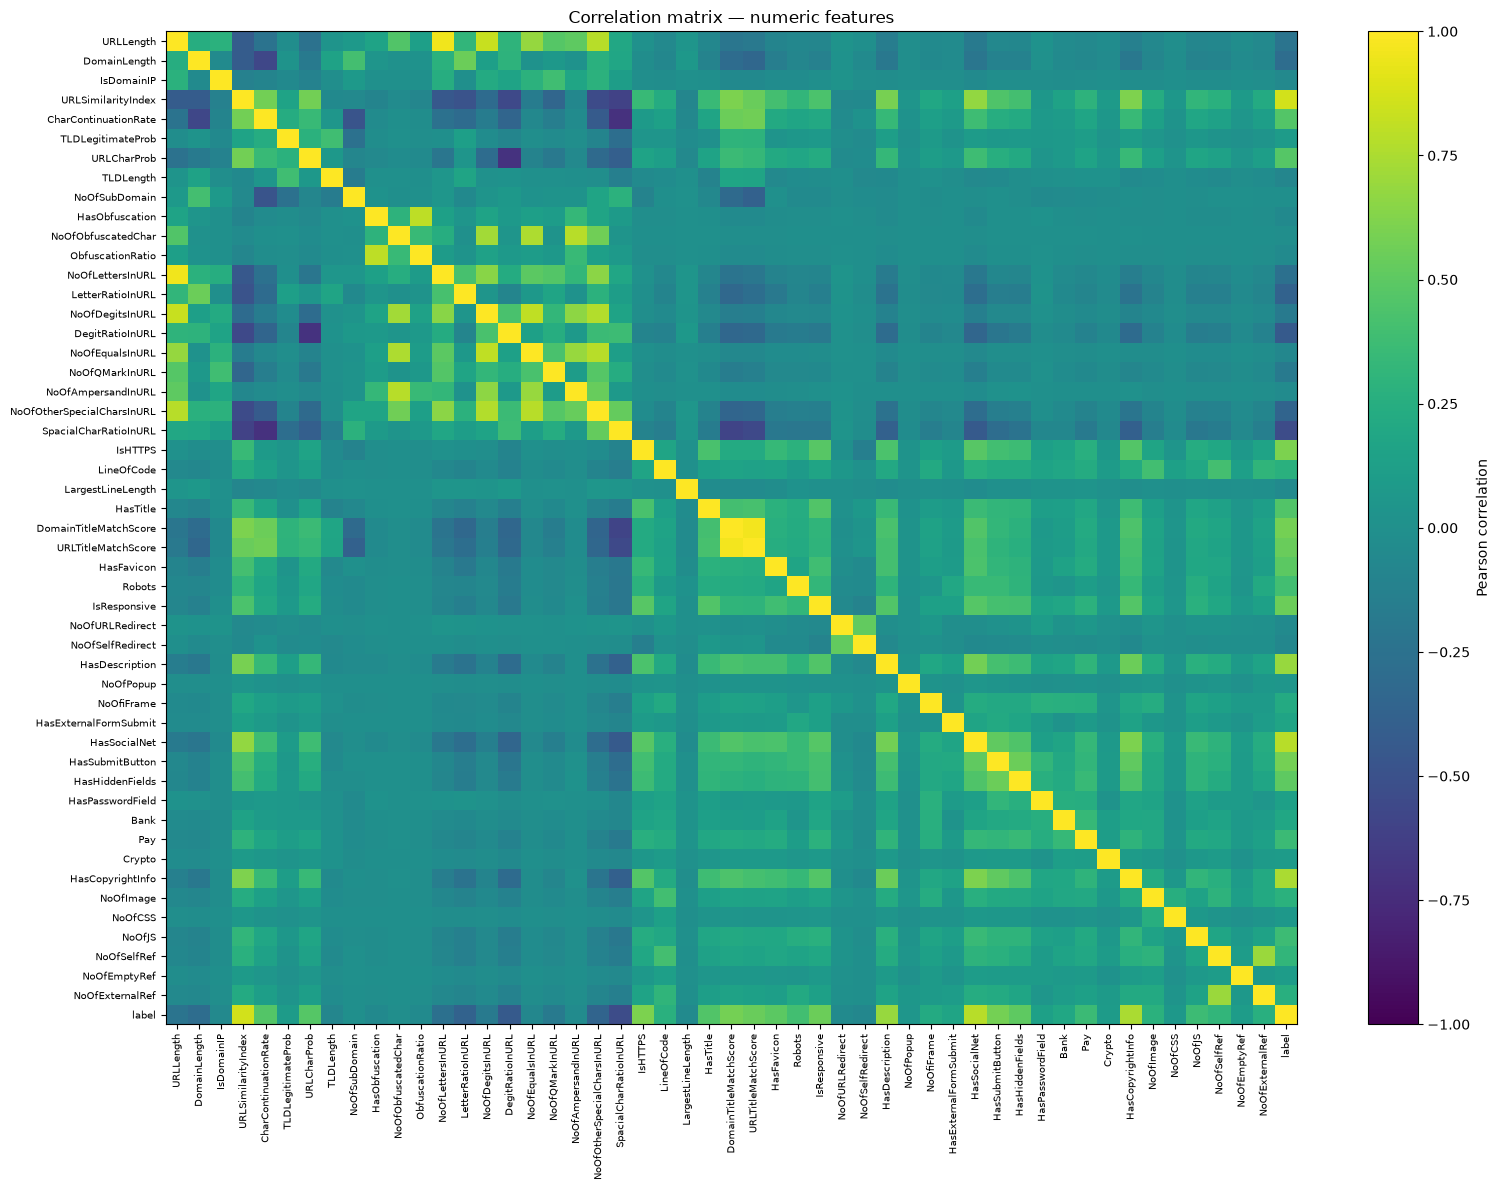

In [7]:
if len(numeric_columns) >= 2:
    corr = df[numeric_columns].corr(numeric_only=True)
    size = min(16, max(8, len(corr) * 0.35))
    plt.figure(figsize=(size, size * 0.75))
    plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    plt.colorbar(label="Pearson correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
    plt.yticks(range(len(corr.index)), corr.index, fontsize=7)
    plt.title("Correlation matrix — numeric features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns.")

In [8]:
import joblib

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(model).__name__)

Model loaded successfully!
Model type: Pipeline


## 8. Load and inspect trained model

In [9]:
# Inspect the already-loaded model
print("Model type:", type(model).__name__)

# Get expected input features
expected_features = getattr(model, "feature_names_in_", None)
if expected_features is not None:
    expected_features = list(expected_features)
    print("\nExpected input columns:", len(expected_features))
    feature_table = pd.DataFrame({
        "Position": range(1, len(expected_features) + 1),
        "Feature Name": expected_features
    })
    display(feature_table)
else:
    print("\nModel does not expose feature_names_in_.")
    
# Inspect pipeline structure
if hasattr(model, "named_steps"):
    print("\nPipeline steps:")
    for step_name, step_object in model.named_steps.items():
        print(f"- {step_name}: {type(step_object).__name__}")

Model type: Pipeline

Expected input columns: 55


,Position,Feature Name
0,1,FILENAME
1,2,URL
2,3,URLLength
3,4,Domain
4,5,DomainLength
5,6,IsDomainIP
6,7,TLD
7,8,URLSimilarityIndex
8,9,CharContinuationRate
9,10,TLDLegitimateProb



Pipeline steps:
- preprocessing: ColumnTransformer
- classifier: RandomForestClassifier


## 9. Dataset/model schema compatibility

In [10]:
missing_from_dataset = []
if expected_features is None:
    print("Cannot compare automatically because feature_names_in_ is unavailable.")
else:
    missing_from_dataset = [c for c in expected_features if c not in df.columns]
    additional_columns = [c for c in df.columns if c not in expected_features and c != TARGET_COLUMN]
    print("Missing required model columns:", len(missing_from_dataset))
    print(missing_from_dataset)
    print("Additional dataset columns:", additional_columns[:30])
    print("Schema check:", "PASS" if not missing_from_dataset else "NOT READY")

Missing required model columns: 0
[]
Additional dataset columns: []
Schema check: PASS


## 10. Optional hold-out evaluation

This section runs only if all expected model input columns are present. It uses a stratified 80/20 split. This is a diagnostic evaluation and may not reproduce the model's original training/evaluation split.

Test records: 47159
Accuracy: 1.0
Precision (weighted): 1.0
Recall (weighted): 1.0
F1 (weighted): 1.0
\nClassification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     20189
           1       1.00      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159



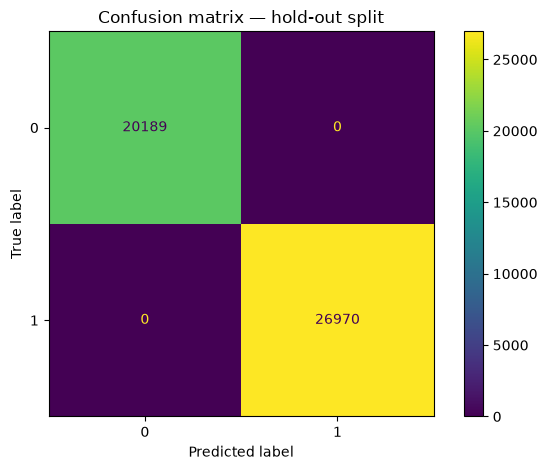

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
if expected_features is None:
    print("Skipped: model input feature names are unavailable.")
elif missing_from_dataset:
    print("Skipped: dataset is missing required model columns.")
else:
    X = df[expected_features].copy()
    y = df[TARGET_COLUMN].copy()
    valid = y.notna()
    X, y = X.loc[valid], y.loc[valid]
    if y.nunique() < 2:
        print("Skipped: target has fewer than two classes.")
    else:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
        )
        predictions = model.predict(X_test)
        print("Test records:", len(X_test))
        print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
        print("Precision (weighted):", round(precision_score(y_test, predictions, average="weighted", zero_division=0), 4))
        print("Recall (weighted):", round(recall_score(y_test, predictions, average="weighted", zero_division=0), 4))
        print("F1 (weighted):", round(f1_score(y_test, predictions, average="weighted", zero_division=0), 4))
        print("\\nClassification report:")
        print(classification_report(y_test, predictions, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(y_test, predictions, values_format="d")
        plt.title("Confusion matrix — hold-out split")
        plt.tight_layout()
        plt.show()

## 11. Feature importance (if supported)

Importance values: 50
Transformed features: 50

Top 20 Important Features:


,Feature,Importance
3,keep_numeric__URLSimilarityIndex,0.173672
49,keep_numeric__NoOfExternalRef,0.169276
22,keep_numeric__LineOfCode,0.153836
47,keep_numeric__NoOfSelfRef,0.106813
44,keep_numeric__NoOfImage,0.093526
46,keep_numeric__NoOfJS,0.069344
36,keep_numeric__HasSocialNet,0.033428
45,keep_numeric__NoOfCSS,0.030517
43,keep_numeric__HasCopyrightInfo,0.024518
21,keep_numeric__IsHTTPS,0.021136


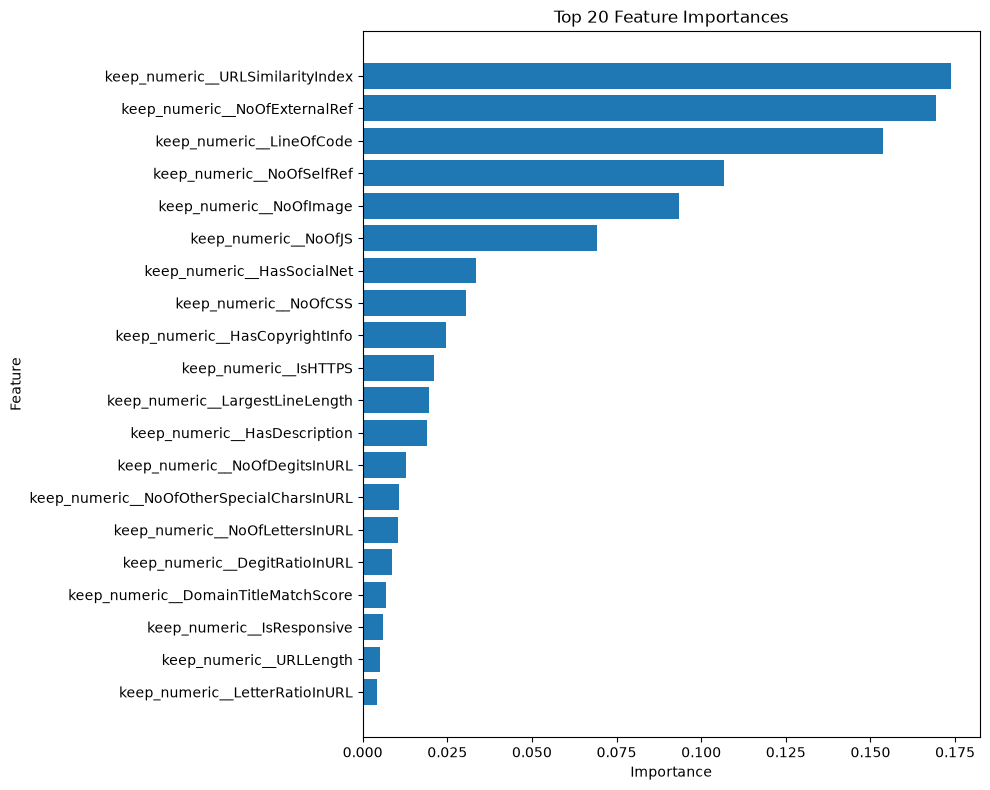

In [12]:

# 11. Feature Importance (if supported)

import pandas as pd
import matplotlib.pyplot as plt

preprocessor = model.named_steps["preprocessing"]
estimator = model.named_steps["classifier"]

if hasattr(estimator, "feature_importances_"):

    importances = estimator.feature_importances_

    # Get feature names after preprocessing
    transformed_features = preprocessor.get_feature_names_out()

    print("Importance values:", len(importances))
    print("Transformed features:", len(transformed_features))

    if len(importances) == len(transformed_features):

        importance_df = pd.DataFrame({
            "Feature": transformed_features,
            "Importance": importances
        })

        importance_df = importance_df.sort_values(
            by="Importance",
            ascending=False
        )

        print("\nTop 20 Important Features:")
        display(importance_df.head(20))

        top = importance_df.head(20).sort_values(
            by="Importance",
            ascending=True
        )

        plt.figure(figsize=(10, 8))
        plt.barh(top["Feature"], top["Importance"])
        plt.title("Top 20 Feature Importances")
        plt.xlabel("Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

    else:
        print("Feature count mismatch. Check preprocessing.")

else:
    print("Classifier does not support feature importance.")


## 12. Findings to complete after execution

Record only the values and patterns produced by this notebook:
- Dataset row and column counts.
- Class counts and verified meaning of each label.
- Missing values and duplicate-row count.
- Patterns observed in feature distributions and correlations.
- Whether the dataset schema matches the model's expected columns.
- Hold-out metrics, if the evaluation cell runs successfully.

## 13. Limitations
- A random split may not reproduce the original evaluation protocol.
- Duplicate URLs or overlapping domains across train and test data can inflate scores.
- Feature definitions and preprocessing must match the model's training-time pipeline.
- High test performance does not guarantee correct predictions for every unseen website.
- PhishGuard AI results are automated indicators, not a guarantee that a website is safe or malicious.

## 14. Conclusion

This notebook provides a reproducible workflow for analysing the PhiUSIIL dataset and inspecting the trained PhishGuard AI model. Add final numerical conclusions after executing it with the project's actual data and model.